# 03 | Describe modeled pollution and source quality

SUPHANATTHAKON THOBSRI | 690631023 | 270702 Data Science Programming

**Scope:** nominal-source-clock-constrained retrospective benchmark. Original historical public release/revision is not certified; operational use remains blocked. Preserve real raw data and never manufacture outcomes.


## Locate the supplied project

Open this notebook inside the extracted project, or upload its complete project ZIP when using Colab. `ROOT` is the project folder; it is not a data-source timestamp. The archive guard rejects paths outside the extraction directory.


In [1]:
from pathlib import Path  # กำหนดตำแหน่งโครงการให้ใช้ได้ในเครื่องและ Colab
import sys  # ใช้โมดูลของโครงการกับ Python ที่กำลังรัน
import os  # อ่านกุญแจจากสภาพแวดล้อมโดยไม่บันทึกค่า
import json  # อ่านค่ากำหนดและข้อมูลอธิบายที่สร้างจริง
import zipfile  # ตรวจและแตกแพ็กเกจโครงการเมื่อจำเป็น
PROJECT_NAME = 'PM25_270702_690631023_Submission'  # ระบุชื่อโครงการฝุ่นและลำดับงานสี่ขั้น
BASE = Path.cwd().resolve()  # ใช้โฟลเดอร์ที่ notebook กำลังรัน
ROOT = BASE if (BASE / 'config.json').is_file() and (BASE / 'src' / 'workflow.py').is_file() else BASE / PROJECT_NAME  # เลือกโครงการที่แตกไฟล์ไว้ก่อน
if not (ROOT / 'src' / 'workflow.py').is_file():  # ค้นหาแพ็กเกจเมื่อเปิด notebook เดี่ยวใน Colab
    if not Path('/content').is_dir():  # การรันในเครื่องต้องมีโครงการที่แตก ZIP อยู่ข้าง notebook
        raise FileNotFoundError('Extract the supplied project ZIP and open its notebook first.')  # หยุดแทนการนำเข้าโค้ดคนละโครงการ
    from google.colab import files  # ขอแพ็กเกจโค้ดและข้อมูลที่มาพร้อม notebook
    uploaded = files.upload()  # อัปโหลด ZIP โครงการที่มีข้อมูลและโค้ดครบ
    archives = [name for name in uploaded if name.lower().endswith('.zip')]  # รับเฉพาะแพ็กเกจ ZIP
    assert len(archives) == 1, 'Upload exactly one project ZIP.'  # หยุดเมื่อเลือกแพ็กเกจได้ไม่แน่นอน
    with zipfile.ZipFile(BASE / archives[0]) as archive:  # เปิด ZIP ที่เลือกเพื่อตรวจความสมบูรณ์
        assert archive.testzip() is None, 'Project ZIP is damaged.'  # ตรวจความสมบูรณ์ ZIP ก่อนแตกไฟล์
        for member in archive.infolist():  # ตรวจปลายทางทุกไฟล์แทนการเชื่อชื่อใน ZIP
            destination = (BASE / member.filename).resolve()  # หาตำแหน่งปลายทางแบบสมบูรณ์ของทุกไฟล์
            assert destination.is_relative_to(BASE), 'Unsafe archive member.'  # ปฏิเสธตำแหน่งไฟล์ที่ออกนอกโฟลเดอร์ทำงาน
        archive.extractall(BASE)  # แตกไฟล์โครงการหลังตรวจความปลอดภัย
assert (ROOT / 'src' / 'workflow.py').is_file(), 'Expected PM2.5 project not found.'  # ตรวจว่ามีโมดูลของโครงการนี้จริง
sys.path.insert(0, str(ROOT / 'src'))  # ใช้โมดูลต้นฉบับที่แนบมากับโครงการ
print('PROJECT:', ROOT)  # แสดงโครงการที่จะรันos.environ['MPLBACKEND'] = 'Agg'  # สร้างไฟล์กราฟโดยไม่เปิดหน้าต่าง
for thread_variable in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']:  # จำกัดเธรดก่อนนำเข้าไลบรารีคำนวณ
    os.environ.setdefault(thread_variable, '1')  # ใช้ค่าเริ่มต้นที่ทำซ้ำได้
os.chdir(ROOT)  # ให้ทุกพาธอ้างโครงการเดียวกัน
from common import load_config  # อ่าน contract รุ่นนี้
ROOT, CONFIG = load_config()  # ตรวจเวลาออกคำทำนายและรุ่นโครงการ
from IPython.display import display, Image, HTML  # แสดงหลักฐานและรูปภาพที่สร้างจริง
import pandas as pd  # อ่านตารางโดยรักษาบทบาทของข้อมูล
import numpy as np  # ตรวจค่าตัวเลขและลำดับเวลา
import workflow as lab  # ใช้ orchestration เดียวกับสคริปต์
from environment_check import check_environment  # ตรวจ dependency ที่ล็อกรุ่น
dependency_evidence = check_environment(ROOT, strict=True)  # ไม่เปลี่ยนรุ่นเงียบ ๆ
display(HTML("<style>.jp-CodeCell .jp-InputArea-editor,.input_area{background:#f2f2f2!important;border:1px solid #ccc}</style>"))  # รักษาพื้นเซลล์โค้ดสีเทา


PROJECT: C:\Users\User\Documents\Codex\2026-10-12\computer-assignment-2-2-string-grammar\outputs\PM25_270702_690631023_Submission


## Load verified preparation outputs

Prepared-table hashes, raw snapshot identity and configuration are checked before analysis. Description uses modeled values over the study calendar. The diagnostic station snapshot remains a separate population.


In [2]:
daily = lab.load_prepared(ROOT, CONFIG)  # ปฏิเสธตารางที่เปลี่ยนหลังเตรียมข้อมูล
from prepare_data import build_experiments  # อ่านชุดทดลองตาม contract เดิม
X, specifications, eligible = build_experiments(ROOT, CONFIG, daily)  # ไม่เลือกตัวแปรใหม่จากความสัมพันธ์ใน test
import analyse as analysis  # ใช้กราฟร่วมกับสคริปต์
annual, monthly = analysis.describe(ROOT, CONFIG, daily)  # สรุปความรุนแรงและฤดูกาลในข้อมูลจำลอง


## Read severity and seasonality with correct denominators

Both full years are reported;2024 is leap year. Threshold exceedances are CAMS-defined, not official measured violations. Two years and changing operational model cycles do not support a secular trend claim. Source-advisory shading does not confirm local contamination.


,valid_days,mean,maximum,exceed_days,exceed_percent
year,,,,,
2024,366,19.550923,44.622731,10,2.732240
2025,365,23.765331,91.883623,30,8.219178


,mean,count,min,max
month,,,,
1,24.445422,62,11.786157,43.726273
2,25.875609,57,11.043325,47.408976
3,34.059051,62,13.158925,91.883623
4,29.260502,60,13.517872,58.311565
5,18.138910,62,6.248853,32.731435
6,12.436838,60,5.515331,26.098048
7,11.960145,62,5.338224,20.993378
8,13.239524,62,6.774941,21.431349
9,16.451402,60,5.444296,37.575906


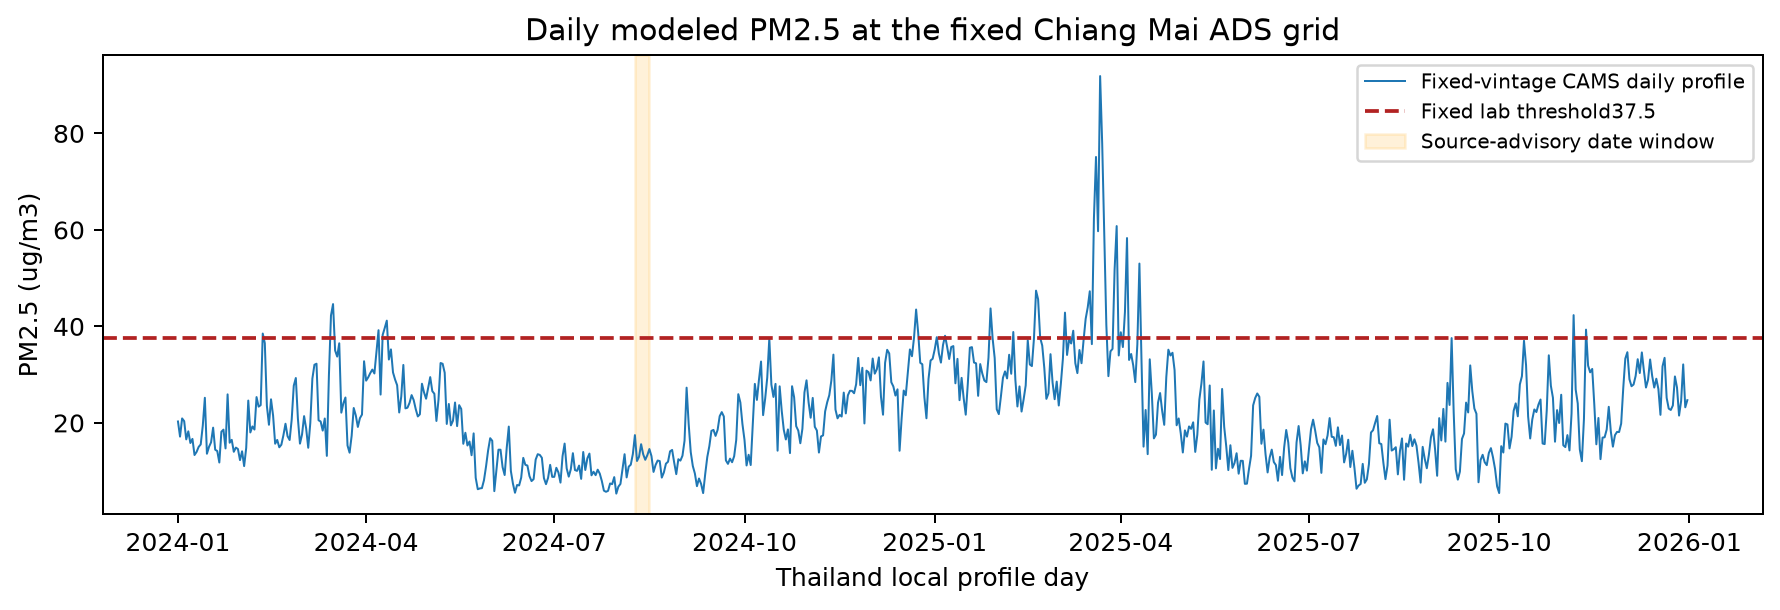

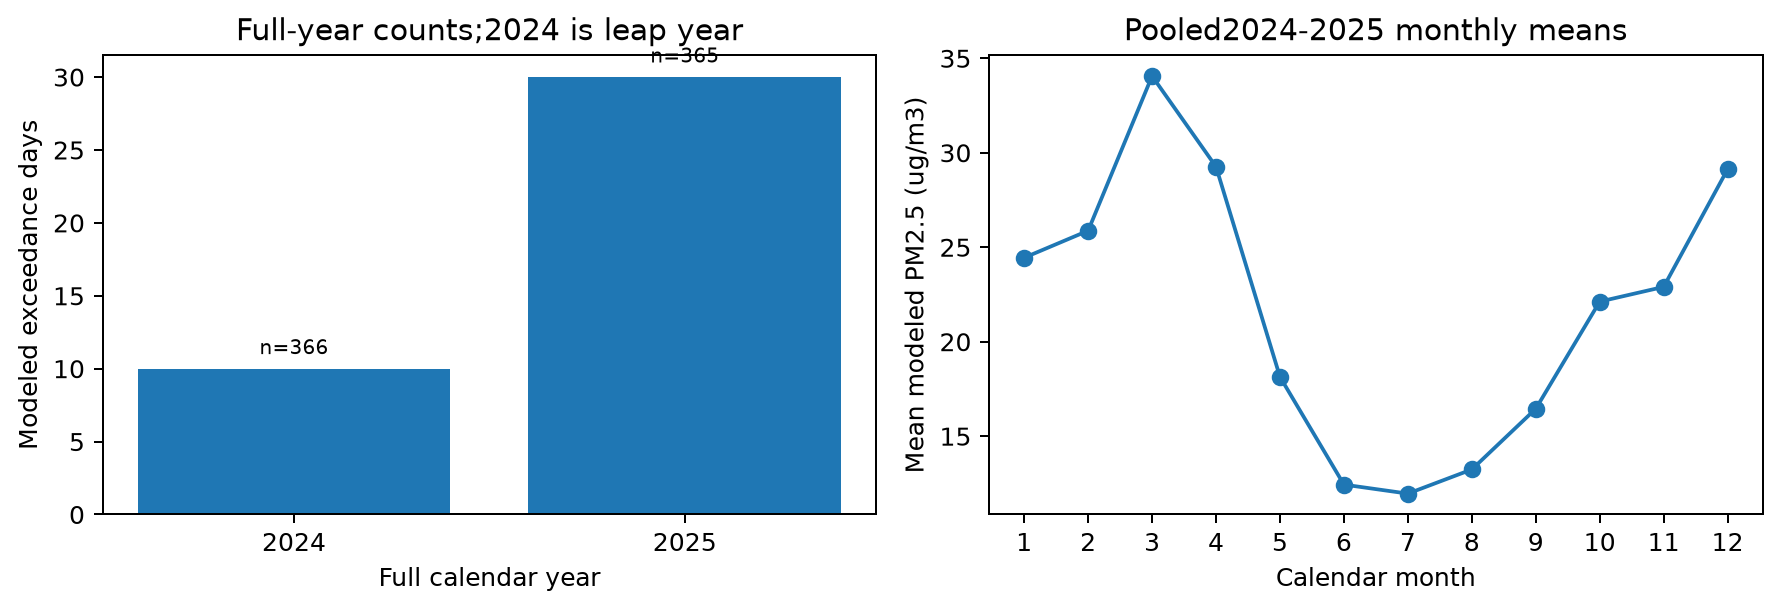

In [3]:
display(annual)  # รายงานจำนวนวันจริงและสัดส่วน ไม่เปรียบเทียบจำนวนโดยลืม denominator
display(monthly)  # ค่าเฉลี่ยรายเดือนจากสองปี ไม่ใช่การพิสูจน์เหตุและผล
display(Image(filename=str(ROOT / 'outputs/figures/01_daily_pm25.png'), width=900))  # แสดงโปรไฟล์และวันที่ต้องระวัง
display(Image(filename=str(ROOT / 'outputs/figures/02_exceedances_seasonality.png'), width=900))  # แสดงจำนวนเกินเกณฑ์และฤดูกาล


## Inspect fire and spatial scope

FRP mean power and observation-opportunity area are separate. Long zero-analysis stretches are visible and never silently treated as sensor completeness. The study has one PM receptor and a regional fire box; source-grid differences are not independent additional study sites. Predictive contributions must be answered by the locked comparisons, not by eyeballing correlations.


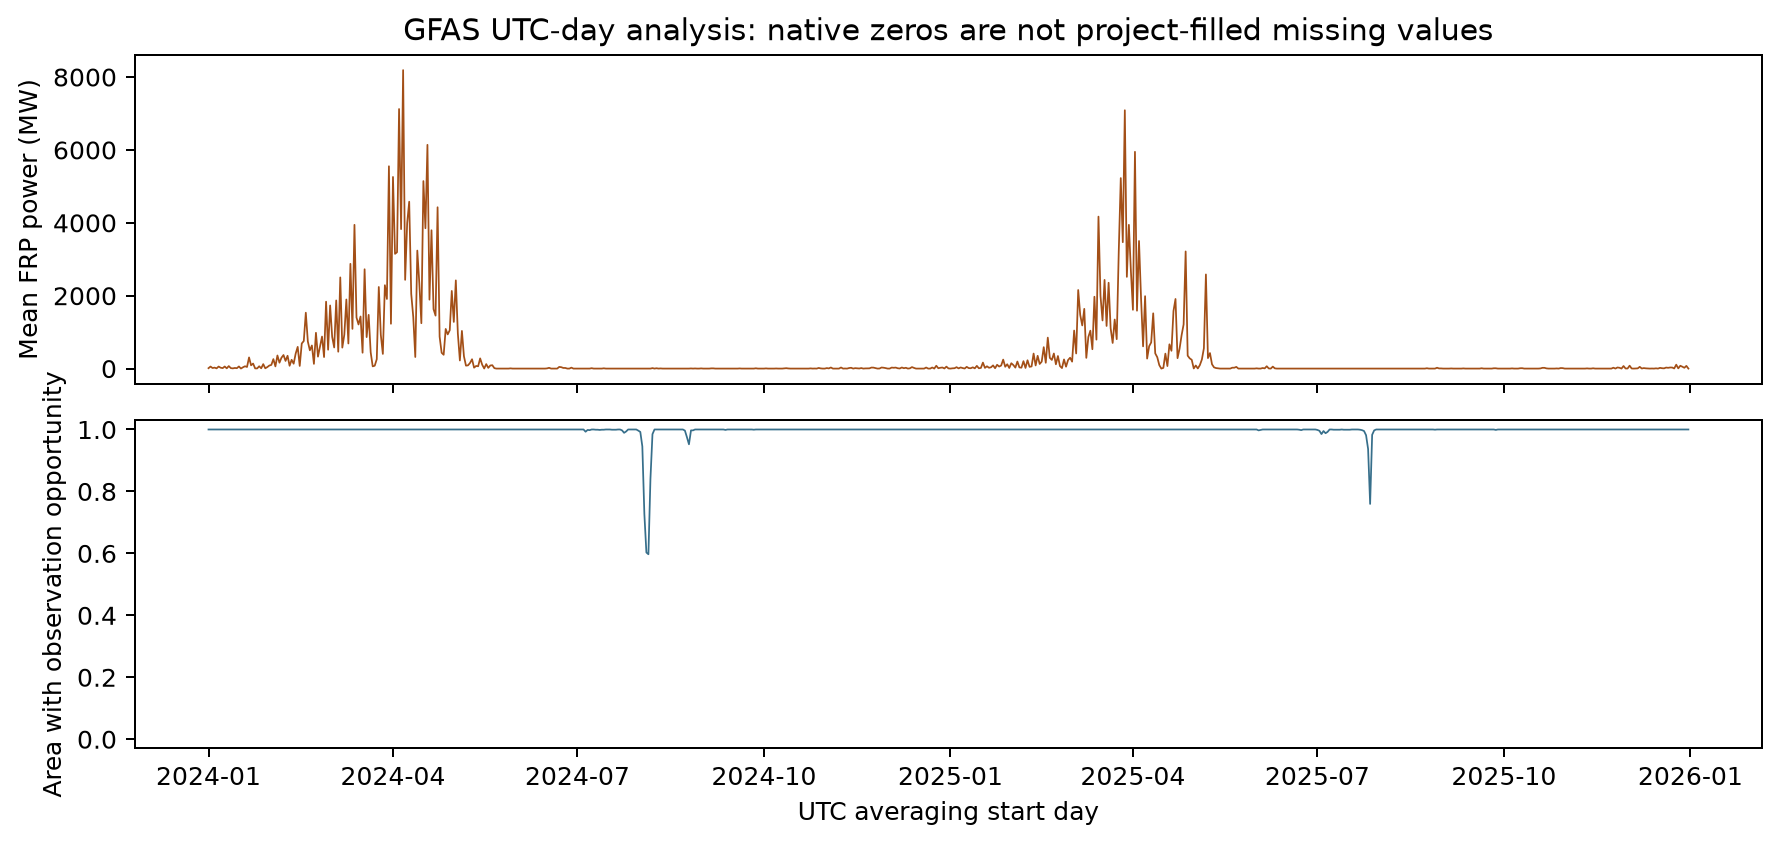

,Spatial item,Evidence
0,status,ONE_RECEPTOR_RETAINED
1,requested_receptor,"{'latitude': 18.7883, 'longitude': 98.9853}"
2,PM_native_ADS_point,"{'latitude': 18.8, 'longitude': 98.8, 'grid_de..."
3,weather_response_grid,"{'latitude': 18.802475, 'longitude': 99.02344}"
4,station_coordinate_comparison,"{'status': 'COMPLETED', 'requested_stations': ..."
5,fire_region,"{'west': 97.0, 'south': 17.5, 'east': 101.0, '..."
6,C4,One receptor; no invented second independent s...
7,C6,Separate preserved contemporary station compar...


,first_local_day,last_local_day,days,mean_pm25,maximum_pm25,kind
0,2024-02-11,2024-02-11,1,38.513839,38.513839,"CAMS modeled exceedance episode, not measured ..."
1,2024-03-15,2024-03-16,2,43.442103,44.622731,"CAMS modeled exceedance episode, not measured ..."
2,2024-04-07,2024-04-07,1,39.211527,39.211527,"CAMS modeled exceedance episode, not measured ..."
3,2024-04-09,2024-04-11,3,39.698485,41.193951,"CAMS modeled exceedance episode, not measured ..."
4,2024-12-22,2024-12-24,3,39.949754,43.495789,"CAMS modeled exceedance episode, not measured ..."
5,2025-01-02,2025-01-02,1,37.767389,37.767389,"CAMS modeled exceedance episode, not measured ..."
6,2025-01-06,2025-01-06,1,38.059540,38.059540,"CAMS modeled exceedance episode, not measured ..."
7,2025-01-28,2025-01-29,2,40.620966,43.726273,"CAMS modeled exceedance episode, not measured ..."
8,2025-02-08,2025-02-08,1,38.837717,38.837717,"CAMS modeled exceedance episode, not measured ..."
9,2025-02-18,2025-02-21,4,42.049285,47.408976,"CAMS modeled exceedance episode, not measured ..."


In [4]:
display(Image(filename=str(ROOT / 'outputs/figures/03_fire_quality.png'), width=900))  # ตรวจค่าศูนย์ไฟกับการสังเกตแยกกัน
display(pd.DataFrame(json.loads((ROOT / 'outputs/results/spatial_resolution_audit.json').read_text(encoding='utf-8')).items(), columns=['Spatial item', 'Evidence']))  # แสดงขอบเขตหนึ่งจุดและกริดต้นทาง
display(pd.read_csv(ROOT / 'outputs/results/exceedance_episodes.csv').head(12))  # ตัวอย่างเหตุการณ์จำลองต่อเนื่องโดยไม่เปลี่ยนการคัดวัน
